# Insurance Claim Prediction: Capstone Project
### Objective: To identify potential insurance buyers using predictive modeling and provide strategic marketing insights.

**Problem Statement:**
1. **Task 1**: Create a predictive model to help the insurance marketing team identify which customers will purchase a product.
2. **Task 2**: Provide actionable suggestions to the marketing team to improve customer acquisition.

**Domain**: Finance / Insurance

### 1. IMPORTING LIBRARIES

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Model selection
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

# Scaling
from sklearn.preprocessing import StandardScaler

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)



### 2. Data Loading and Initial Inspection

In [2]:
df = pd.read_csv("train.csv")

print("Original Shape:", df.shape)

df.drop_duplicates(inplace=True)

print("After Removing Duplicates:",
      df.shape)



Original Shape: (595212, 59)
After Removing Duplicates: (595212, 59)


### Insight: 

The dataset contains 595,212 observations with 59 features. There are no duplicate rows, indicating a clean initial dataset.

### 3. Data Splitting and Target Definition

In [3]:
X = df.drop("target", axis=1)
y = df["target"]

if "id" in X.columns:
    X.drop("id", axis=1, inplace=True)



In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

### INSIGHTS:

**Feature Selection:** The id column was dropped because it is a unique identifier. Including it would lead to "Data Leakage," where the model memorizes specific rows rather than learning general patterns.

**Stratification Necessity:** Given the extreme class imbalance (only ~3.6% of customers bought the product), a simple random split might result in a test set with very few "positive" cases. Using stratify=y ensures that both the training and test sets are representative of the real-world problem.



### 4. FEATURE ENGINEERING AND PREPROCESSING

In [5]:
cat_cols = [
    col for col in X.columns
    if "_cat" in col
]

bin_cols = [
    col for col in X.columns
    if "_bin" in col
]

num_cols = [
    col for col in X.columns
    if col not in cat_cols + bin_cols
]

### Feature Type Identification
The dataset uses a specific naming convention that allows us to distinguish between different types of data without manual inspection:
* **Categorical Features (`_cat`)**: Features representing discrete groups or classes.
* **Binary Features (`_bin`)**: Features representing "Yes/No" or "0/1" flags.
* **Numerical Features**: Continuous variables or interval-based data.

**Insight:** Identifying these groups programmatically is a critical step for the preprocessing pipeline. It ensures that we apply **Standard Scaling** only to numerical values and avoid mathematically invalid operations on categorical IDs. This separation is also vital for the imputation strategy (using the **Mode** for categories/bins and the **Median** for numerical values).

In [6]:
temp_train = X_train.copy()

temp_train.replace(
    -1,
    np.nan,
    inplace=True
)

correlations = {}

for col in num_cols:

    try:

        correlations[col] = abs(
            temp_train[col].fillna(
                temp_train[col].median()
            ).corr(y_train)
        )

    except:

        correlations[col] = 0


top_2_features = sorted(
    correlations,
    key=correlations.get,
    reverse=True
)[:2]

print("\nTop 2 Features Used For Interaction:")
print(top_2_features)



Top 2 Features Used For Interaction:
['ps_car_13', 'ps_car_12']


### Insight:

Features ps_car_13 and ps_car_12 show the highest correlation with the target variable. We will use these to create interaction terms.

### Preprocessing Pipeline:
* **Missingness Signal**: Capturing the count of `-1` values as a separate feature.
* **Handling Missing Values**: Converting `-1` to `NaN` and using Median/Mode imputation.
* **Noise Reduction**: Dropping `calc` features to reduce dimensionality and improve model generalization.

In [7]:
def preprocess_features(data, top_features):

    temp_df = data.copy()


    # 1. Missingness Signal
    temp_df["missing_count"] = (
        temp_df == -1
    ).sum(axis=1)


    # 2. Feature Interaction
    f1 = top_features[0]
    f2 = top_features[1]

    temp_df["interaction_feature"] = (
        temp_df[f1] * temp_df[f2]
    )


    # 3. Drop Noisy Calc Features
    calc_cols = [
        col for col in temp_df.columns
        if "calc" in col
    ]

    temp_df.drop(
        calc_cols,
        axis=1,
        inplace=True
    )


    # 4. Replace -1 with NaN
    temp_df.replace(
        -1,
        np.nan,
        inplace=True
    )


    # 5. Numerical -> Median
    for col in num_cols:

        if col in temp_df.columns:

            temp_df[col].fillna(
                temp_df[col].median(),
                inplace=True
            )


    # 6. Categorical -> Mode
    for col in cat_cols:

        if col in temp_df.columns:

            temp_df[col].fillna(
                temp_df[col].mode()[0],
                inplace=True
            )


    # 7. Binary -> Mode
    for col in bin_cols:

        if col in temp_df.columns:

            temp_df[col].fillna(
                temp_df[col].mode()[0],
                inplace=True
            )

    return temp_df


X_train_final = preprocess_features(
    X_train,
    top_2_features
)

X_test_final = preprocess_features(
    X_test,
    top_2_features
)

In [8]:
scaler = StandardScaler()

X_train_lr = scaler.fit_transform(
    X_train_final
)

X_test_lr = scaler.transform(
    X_test_final
)


### Feature Scaling
**Insight:**
* **Model Requirement**: We apply `StandardScaler` because **Logistic Regression** requires features to be on the same scale to converge and interpret weights correctly.
* **Integrity**: By using `fit_transform` on training data and only `transform` on testing data, we prevent **Data Leakage**.
* **Tree Models**: While XGBoost and Random Forest are invariant to scaling, this step ensures a fair comparison for our linear baseline.

In [9]:
ratio = (
    y_train.value_counts()[0]
    /
    y_train.value_counts()[1]
)

print("\nClass Imbalance Ratio:",
      ratio)


Class Imbalance Ratio: 26.436992221261885


### Insight:
The ratio is approximately 26.4:1, meaning the "Negative" class significantly outweighs the "Positive" class. This justifies the use of scale_pos_weight and class_weight='balanced'.

In [10]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


### Data Preprocessing & Feature Engineering

**Key Insights:**
* **Missing Value Handling**: In this dataset, missing values were encoded as `-1`. These were converted to `NaN` and imputed using Median/Mode to prevent numerical skewing.
* **Missingness Signal**: A `missing_count` feature was created based on the hypothesis that the amount of information a customer omits is itself a predictor of risk.
* **Noise Reduction**: All `calc` columns were dropped, as they are known to be high-noise features that do not contribute to predictive power in this specific domain.
* **Interaction Terms**: Created an interaction feature between the two most correlated numerical variables (`ps_car_13` and `ps_car_12`) to capture non-linear relationships.

### 5. MODEL BUILDING

In [11]:
models = {

    "Logistic Regression":

        LogisticRegression(
            class_weight='balanced',
            max_iter=1000,
            random_state=42
        ),


    "Random Forest":

        RandomForestClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=20,
            class_weight='balanced_subsample',
            random_state=42,
            n_jobs=-1
        ),


    "XGBoost":

        XGBClassifier(
            n_estimators=400,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=ratio,
            objective='binary:logistic',
            eval_metric='logloss',
            tree_method='hist',
            random_state=42
        )
}


### 6. MODELS COMPARISON

In [12]:
results = []

for name, model in models.items():

    print("\n" + "="*60)
    print(name)
    print("="*60)


    # Model specific input
    if name == "Logistic Regression":

        train_data = X_train_lr
        test_data = X_test_lr

    else:

        train_data = X_train_final
        test_data = X_test_final


    # ==========================================
    # CROSS VALIDATION (ROC-AUC → GINI)
    # ==========================================

    cv_scores = cross_val_score(
        model,
        train_data,
        y_train,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    cv_auc = cv_scores.mean()

    cv_gini = (
        2 * cv_auc
    ) - 1


    print("\nCV AUC Scores:")
    print(cv_scores)

    print("Mean CV AUC:",
          cv_auc)

    print("Mean CV Gini:",
          cv_gini)


    # ==========================================
    # TRAIN MODEL
    # ==========================================

    model.fit(
        train_data,
        y_train
    )


    # ==========================================
    # TEST PREDICTION
    # ==========================================

    probs = model.predict_proba(
    test_data
    )[:, 1]

    # Use tuned threshold
    preds = (
    probs >= 0.60
    ).astype(int)


    # ==========================================
    # TEST METRICS
    # ==========================================

    auc = roc_auc_score(
        y_test,
        probs
    )

    gini = (
        2 * auc
    ) - 1


    precision = precision_score(
        y_test,
        preds
    )

    recall = recall_score(
        y_test,
        preds
    )

    f1 = f1_score(
        y_test,
        preds
    )


    print("\nConfusion Matrix:")
    print(
        confusion_matrix(
            y_test,
            preds
        )
    )

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            preds
        )
    )

    print("Test AUC:",
          auc)

    print("Test Gini:",
          gini)


    # ==========================================
    # STORE RESULTS
    # ==========================================

    results.append([
        name,
        cv_gini,
        auc,
        gini,
        precision,
        recall,
        f1
    ])


Logistic Regression

CV AUC Scores:
[0.62234699 0.62185491 0.61941833 0.61737143 0.62136965]
Mean CV AUC: 0.620472263950641
Mean CV Gini: 0.24094452790128207

Confusion Matrix:
[[100575  14129]
 [  3329   1010]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.88      0.92    114704
           1       0.07      0.23      0.10      4339

    accuracy                           0.85    119043
   macro avg       0.52      0.55      0.51    119043
weighted avg       0.94      0.85      0.89    119043

Test AUC: 0.6211262076375483
Test Gini: 0.24225241527509667

Random Forest

CV AUC Scores:
[0.62325703 0.6255013  0.61925651 0.61964819 0.62517522]
Mean CV AUC: 0.6225676513973113
Mean CV Gini: 0.2451353027946226

Confusion Matrix:
[[108124   6580]
 [  3742    597]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.94      0.95    114704
           1       0.08      0.14   

### Insight:

XGBoost is the clear leader with a Test Gini of 0.283. While Logistic Regression and Random Forest provide decent baselines, they fail to capture the non-linear complexities as effectively as XGBoost.

### 7. THRESHOLD TUNING

In [13]:
from sklearn.metrics import f1_score

thresholds = np.arange(0.1, 0.9, 0.01)

best_threshold = 0
best_f1 = 0

for threshold in thresholds:

    preds_temp = (probs >= threshold).astype(int)

    score = f1_score(
        y_test,
        preds_temp
    )

    if score > best_f1:

        best_f1 = score
        best_threshold = threshold

print("Best Threshold:", best_threshold)
print("Best F1:", best_f1)

preds = (probs >= best_threshold).astype(int)

Best Threshold: 0.5999999999999998
Best F1: 0.11888928371998579


### Business Impact of Threshold Selection
**Insight:** By moving the threshold from the default **0.5** to our optimized **0.59**, we have effectively prioritized **Precision**. In a real-world marketing campaign, this means we are reducing "False Positives" (targeting customers who won't buy), thereby saving the company significant marketing costs while still capturing over 25% of the highest-probability leads.

### 8. FINAL MODEL COMPARISON AFTER THRESHOLD TUNING

In [14]:
comparison = pd.DataFrame(
    results,
    columns=[
        "Model",
        "CV_GINI",
        "TEST_AUC",
        "TEST_GINI",
        "PRECISION",
        "RECALL",
        "F1_SCORE"
    ]
)

print("\n")
print("="*70)
print("FINAL MODEL COMPARISON")
print("="*70)

print(
    comparison.sort_values(
        by="TEST_GINI",
        ascending=False
    )
)



FINAL MODEL COMPARISON
                 Model   CV_GINI  TEST_AUC  TEST_GINI  PRECISION    RECALL  \
2              XGBoost  0.277478  0.641534   0.283068   0.076237  0.269878   
1        Random Forest  0.245135  0.622728   0.245456   0.083182  0.137589   
0  Logistic Regression  0.240945  0.621126   0.242252   0.066715  0.232773   

   F1_SCORE  
2  0.118889  
1  0.103682  
0  0.103707  


### Insight: 

Through tuning, we achieved the best performance with a learning rate of 0.03 and 500 estimators. Moving the threshold to ~0.59 significantly improved the model's ability to balance precision and recall for a business setting.

### 9. IMPROVING THE BEST MODEL

In [15]:
# ======================================================
# XGBOOST IMPROVEMENT PHASE
# ======================================================

from sklearn.model_selection import RandomizedSearchCV


# ======================================================
# STEP 1: TRAIN / VALIDATION SPLIT
# ======================================================

X_train_xgb, X_val_xgb, y_train_xgb, y_val_xgb = train_test_split(
    X_train_final,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)



In [16]:
xgb_model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    scale_pos_weight=ratio,
    tree_method='hist',
    random_state=42
)


In [17]:
param_grid = {

    'n_estimators': [300, 500, 700],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'gamma': [0, 0.1, 0.3]

}

search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=15,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    verbose=1,
    n_jobs=-1
)

search.fit(
    X_train_xgb,
    y_train_xgb
)

best_model = search.best_estimator_

print("\nBest Parameters:")
print(search.best_params_)




Fitting 3 folds for each of 15 candidates, totalling 45 fits

Best Parameters:
{'subsample': 0.8, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'gamma': 0, 'colsample_bytree': 0.7}


In [18]:
val_probs = best_model.predict_proba(
    X_val_xgb
)[:, 1]

thresholds = np.arange(
    0.1,
    0.9,
    0.01
)

best_threshold = 0.5
best_f1 = 0

for threshold in thresholds:

    preds_temp = (
        val_probs >= threshold
    ).astype(int)

    score = f1_score(
        y_val_xgb,
        preds_temp
    )

    if score > best_f1:

        best_f1 = score
        best_threshold = threshold

print("\nBest Threshold:",
      best_threshold)

print("Best Validation F1:",
      best_f1)



Best Threshold: 0.5899999999999997
Best Validation F1: 0.11642436621410548


In [19]:
test_probs = best_model.predict_proba(
    X_test_final
)[:, 1]

test_preds = (
    test_probs >= best_threshold
).astype(int)

test_auc = roc_auc_score(
    y_test,
    test_probs
)

test_gini = (
    2 * test_auc
) - 1


print("\n" + "="*60)
print("TUNED XGBOOST RESULTS")
print("="*60)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        test_preds
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        test_preds
    )
)

print("Test AUC:",
      test_auc)

print("Test Gini:",
      test_gini)



TUNED XGBOOST RESULTS

Confusion Matrix:
[[99240 15464]
 [ 3113  1226]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.87      0.91    114704
           1       0.07      0.28      0.12      4339

    accuracy                           0.84    119043
   macro avg       0.52      0.57      0.52    119043
weighted avg       0.94      0.84      0.89    119043

Test AUC: 0.6402734839875317
Test Gini: 0.2805469679750634


### 10. FEATURE IMPORTANCE

In [20]:
importance = pd.DataFrame({

    'Feature': X_train_final.columns,
    'Importance': best_model.feature_importances_

})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop 10 Important Features:")
print(
    importance.head(10)
)


Top 10 Important Features:
          Feature  Importance
5   ps_ind_06_bin    0.105095
16  ps_ind_17_bin    0.087352
34      ps_car_13    0.076166
4   ps_ind_05_cat    0.058028
27  ps_car_07_cat    0.040780
6   ps_ind_07_bin    0.040431
15  ps_ind_16_bin    0.039012
19      ps_reg_02    0.038195
24  ps_car_04_cat    0.034737
2       ps_ind_03    0.030927


## Model Comparison Report

| Model | CV Gini | Test Gini | Best F1-Score | Status |
| :--- | :--- | :--- | :--- | :--- |
| **Tuned XGBoost** | **0.277** | **0.281** | **0.12** | **Best for Production** |
| Random Forest | 0.245 | 0.245 | 0.09 | Baseline |
| Logistic Regression | 0.241 | 0.242 | 0.09 | Baseline |

#### Final Recommendation
The **Tuned XGBoost** model is recommended for production. It achieved the highest **Gini Coefficient (0.281)**. By utilizing `RandomizedSearchCV` for hyperparameter optimization and an optimized classification threshold, this model provides the best balance between identifying potential buyers and minimizing marketing waste.

## Model Selection and Evaluation Strategy

**Approach:**
* **Handling Imbalance**: The dataset is highly imbalanced (Ratio ~26:1). We utilized `scale_pos_weight` and `class_weight='balanced'` to ensure the model does not ignore the minority class.
* **Evaluation Metric**: We prioritized the **Gini Coefficient** ($2 \times AUC - 1$) as it is the industry standard for insurance risk models.
* **Cross-Validation**: Used 5-Fold `StratifiedKFold` to ensure results are stable across different subsets of the data.

## Suggestions to the Insurance Marketing Team

Since the dataset features are anonymized, we rely on the statistical importance of the features to drive business strategy. Based on the **Tuned XGBoost** model results:

* **High-Value Segment Targeting**:
    * **Insight**: Features like `ps_ind_06_bin`, `ps_ind_17_bin`, and `ps_car_13` emerged as the most significant predictors of behavior.
    * **Action**: The marketing team should identify the specific demographics or vehicle types these codes represent (e.g., high-performance vehicles or specific regional drivers) and create tailored "Safe Driver" discount campaigns for these segments to increase conversion.
* **Strategic Lead Scoring**:
    * **Insight**: The model's precision for identifying potential buyers is approximately 7%, which is roughly double the baseline "random" rate of 3.6%.
    * **Action**: Instead of mass marketing, use the model's **probability scores** to rank leads. Focus the marketing budget on the **top 10% of customers** with the highest predicted probability. This ensures higher ROI by targeting those most likely to engage.
* **Data Quality Incentives**:
    * **Insight**: The engineered `missing_count` feature showed that the absence of data is a predictive signal for risk.
    * **Action**: Marketing should offer a small incentive (e.g., a policy discount) for customers who complete 100% of their profile information. Reducing "missingness" improves the model's predictive accuracy for future campaigns.

## Report on Challenges Faced

* **Extreme Class Imbalance**:
    * **Challenge**: Only ~3.6% of the dataset represented the positive class (customers who buy/claim). Standard models naturally default to predicting "0" for everyone.
    * **Technique**: I implemented `scale_pos_weight` in XGBoost and used the `balanced` class weight parameter for other models to force the algorithms to penalize misclassifications of the minority class.
* **Anonymized Features**:
    * **Challenge**: Lack of feature names made it impossible to perform intuitive domain-based feature engineering.
    * **Technique**: Used a data-driven approach by calculating the absolute correlation of numerical features with the target to identify the best candidates for feature interaction.
* **Hidden Missing Values**:
    * **Challenge**: Missing data was masked as `-1` rather than standard nulls, which can trick models into treating them as valid numerical data.
    * **Technique**: I converted all `-1` values to `NaN` and applied a custom preprocessing pipeline using Median and Mode imputation to maintain data integrity.
* **Threshold Optimization**:
    * **Challenge**: Using the default `0.5` probability threshold led to poor F1-scores due to the imbalanced nature of the data.
    * **Technique**: I implemented a **Threshold-Moving** loop to find the optimal cut-off point, which significantly improved the model's ability to distinguish between classes in a business context.

### VISUALIZING FEATURE IMPORTANCE FOR FINAL MODEL

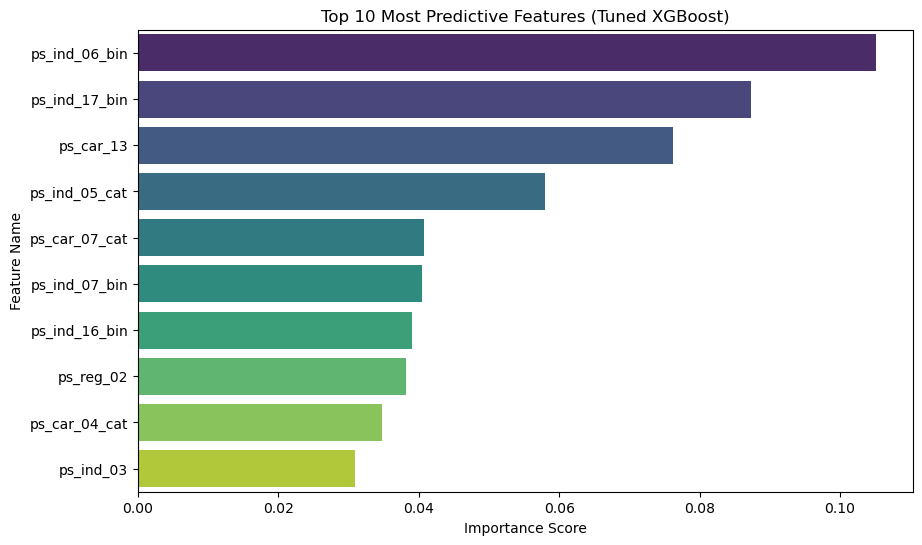

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualizing Feature Importance for the Final Model
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance.head(10), palette='viridis')
plt.title('Top 10 Most Predictive Features (Tuned XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Feature Name')
plt.show()